<a href="https://colab.research.google.com/github/LauraEar1/BMEN600_22/blob/laura-branch-datacleaning/CAP_sleep_analysis_clean_annotated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CAP Sleep Database — Annotation Cleaning and Multimodal Signal Exploration

**Objective:** Prepare expert-annotated CAP A-phase events and inspect physiological signals for a future comparison of EEG-only and multimodal CAP A-phase classifiers.

**Scope:** Descriptive analysis of 88 selected annotation files and an initial raw-signal feasibility check using `nfle1.edf`. **No machine-learning model is trained in this notebook.**

**How to use:** Run cells in order in Google Colab. Annotation files are small and can be downloaded again if needed. The ~510 MB EDF is **not** downloaded automatically; provide its location in the configuration cell.

**Source:** [PhysioNet CAP Sleep Database](https://physionet.org/content/capslpdb/1.0.0/).

## 1. Setup and file locations

Set `EDF_PATH` to the location of your existing EDF file. Files under `/content/` disappear when the Colab runtime resets. To use a file stored elsewhere, first transfer it into Colab or mount an accessible drive.

In [11]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [14]:
%pip install -q mne

from pathlib import Path
from collections import Counter
import urllib.request
import urllib.error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import mne

BASE_URL = "https://physionet.org/files/capslpdb/1.0.0/"
DATA_DIR = Path("/content/cap_sleep_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)
EDF_PATH = Path("/content/drive/MyDrive/CAP_Sleep_Database/nfle1.edf")  # Will likely need to update to be scalable at a later date
OUTPUT_DIR = DATA_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Annotation directory:", DATA_DIR)
print("EDF path:", EDF_PATH)

Annotation directory: /content/cap_sleep_data
EDF path: /content/drive/MyDrive/CAP_Sleep_Database/nfle1.edf


## 2. Participant distribution

The reported database group counts below describe the broader database. Our analysis selects healthy controls, NFLE, PLM, and RBD; the exact participant IDs are confirmed against the `RECORDS` manifest in the next section.

,Diagnostic group,Participants,Selected,Percent_of_database
0,Healthy controls,16,True,14.81
1,Bruxism,2,False,1.85
2,Insomnia,9,False,8.33
3,Narcolepsy,5,False,4.63
4,NFLE,40,True,37.04
5,Periodic leg movements (PLM),10,True,9.26
6,REM behaviour disorder (RBD),22,True,20.37
7,Sleep-disordered breathing,4,False,3.70


Selected participants (reported): 88


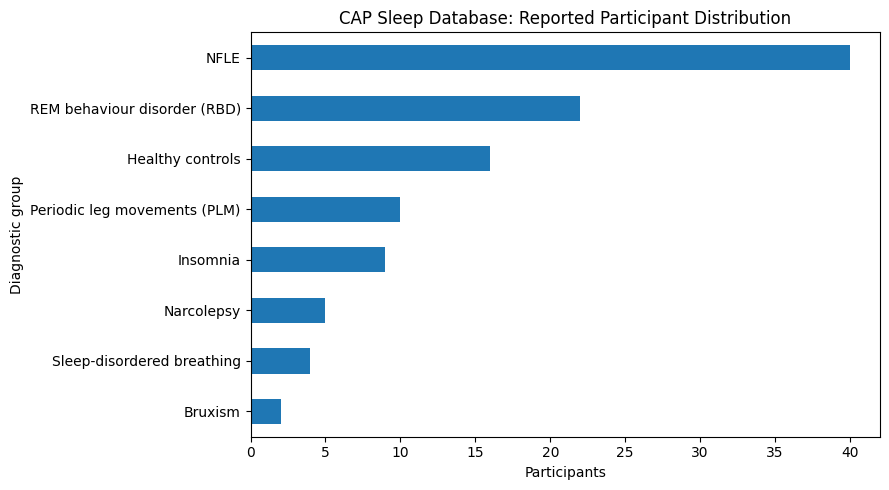

In [2]:
reported_counts = {
    "Healthy controls": 16, "Bruxism": 2, "Insomnia": 9,
    "Narcolepsy": 5, "NFLE": 40,
    "Periodic leg movements (PLM)": 10,
    "REM behaviour disorder (RBD)": 22,
    "Sleep-disordered breathing": 4,
}
selected_groups = {"Healthy controls", "NFLE", "Periodic leg movements (PLM)", "REM behaviour disorder (RBD)"}
group_distribution = pd.DataFrame(reported_counts.items(), columns=["Diagnostic group", "Participants"])
group_distribution["Selected"] = group_distribution["Diagnostic group"].isin(selected_groups)
group_distribution["Percent_of_database"] = (100 * group_distribution["Participants"] / group_distribution["Participants"].sum()).round(2)
display(group_distribution)
print("Selected participants (reported):", group_distribution.loc[group_distribution["Selected"], "Participants"].sum())
ax = group_distribution.sort_values("Participants").plot.barh(x="Diagnostic group", y="Participants", legend=False, figsize=(9, 5))
ax.set(xlabel="Participants", ylabel="Diagnostic group", title="CAP Sleep Database: Reported Participant Distribution")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cap_group_counts.png", dpi=300, bbox_inches="tight")
plt.show()
group_distribution.to_csv(OUTPUT_DIR / "cap_group_counts.csv", index=False)

## 3. Select participants and retrieve annotations

The `RECORDS` manifest supplies EDF identifiers. Only the `.txt` annotation files are downloaded here; existing copies are reused. This section should identify **88** participants.

In [3]:
manifest_path = DATA_DIR / "RECORDS"
if not manifest_path.exists():
    urllib.request.urlretrieve(BASE_URL + "RECORDS", manifest_path)
records = [line.strip() for line in manifest_path.read_text().splitlines() if line.strip()]

def identify_group(pid):
    if pid.startswith("nfle"): return "NFLE"
    if pid.startswith("rbd"): return "RBD"
    if pid.startswith("plm"): return "PLM"
    if pid.startswith("n") and pid[1:].isdigit(): return "Healthy control"
    return None

selected_participants = [(Path(rec).stem, identify_group(Path(rec).stem)) for rec in records]
selected_participants = [(pid, group) for pid, group in selected_participants if group is not None]
print("Selected participants:", len(selected_participants))
print("By group:", dict(Counter(group for _, group in selected_participants)))
assert len(selected_participants) == 88, "Unexpected participant count: check RECORDS and selection criteria."

Selected participants: 88
By group: {'Healthy control': 16, 'NFLE': 40, 'PLM': 10, 'RBD': 22}


In [4]:
downloaded_files, failed_files = [], []
for pid, group in selected_participants:
    filepath = DATA_DIR / f"{pid}.txt"
    try:
        if not filepath.exists() or filepath.stat().st_size == 0:
            urllib.request.urlretrieve(BASE_URL + filepath.name, filepath)
        downloaded_files.append((pid, group, filepath))
    except (urllib.error.URLError, OSError) as exc:
        failed_files.append((pid, str(exc)))
print("Available annotation files:", len(downloaded_files))
print("Failures:", failed_files[:10])
if failed_files:
    raise RuntimeError("Some annotations are missing. Resolve downloads before proceeding.")

Available annotation files: 88
Failures: []


## 4. Parse and validate annotation tables

The source files contain a textual preamble before the tab-separated event table. The parser finds the header, standardizes the `Duration [s]`/`Duration[s]` variation (including `n16` which contaned a typo,extra space, in the column name), and excludes records missing an event, clock time, or valid duration. Review excluded rows before interpreting the results.

In [5]:
all_annotations, parsing_errors = [], []
for pid, group, filepath in downloaded_files:
    try:
        with filepath.open(encoding="utf-8", errors="replace") as f:
            lines = f.readlines()
        header_index = next(i for i, line in enumerate(lines) if line.startswith("Sleep Stage"))
        part = pd.read_csv(filepath, sep="\t", skiprows=header_index, encoding="utf-8", encoding_errors="replace", on_bad_lines="skip")
        part.columns = part.columns.str.strip()
        part = part.rename(columns={"Duration [s]": "Duration[s]"})
        for required in ["Event", "Time [hh:mm:ss]", "Duration[s]"]:
            if required not in part.columns:
                raise ValueError(f"Missing column {required}")
        part["Participant"] = pid
        part["Group"] = group
        all_annotations.append(part)
    except Exception as exc:
        parsing_errors.append((pid, str(exc)))
if parsing_errors:
    raise RuntimeError(f"Annotation parsing errors: {parsing_errors}")
df_all = pd.concat(all_annotations, ignore_index=True)
df_all["Event"] = df_all["Event"].astype("string").str.strip()
df_all["Duration[s]"] = pd.to_numeric(df_all["Duration[s]"], errors="coerce")
df_all["Time [hh:mm:ss]"] = df_all["Time [hh:mm:ss]"].astype("string").str.strip()
parsed_clock = pd.to_timedelta(df_all["Time [hh:mm:ss]"], errors="coerce")
invalid = (df_all["Event"].isna() | parsed_clock.isna() | df_all["Duration[s]"].isna() | (df_all["Duration[s]"] < 0))
excluded_rows = df_all.loc[invalid].copy()
df_all_cap = df_all.loc[~invalid].copy().reset_index(drop=True)
print("Participants retained:", df_all_cap["Participant"].nunique())
print("Annotation rows retained:", len(df_all_cap))
print("Excluded malformed rows:", len(excluded_rows))
display(excluded_rows)
assert df_all_cap["Participant"].nunique() == 88, "Some participants were lost during parsing."

Participants retained: 88
Annotation rows retained: 130789
Excluded malformed rows: 2


,Sleep Stage,Position,Time [hh:mm:ss],Event,Duration[s],Location,Participant,Group
9579,NaN,NaN,<NA>,<NA>,NaN,NaN,n16,Healthy control
52503,S2,Unknown Position,04:54:0,<NA>,NaN,NaN,nfle27,NFLE


## 5. CAP A-phase descriptive analysis

`MCAP-A1`, `MCAP-A2`, and `MCAP-A3` are expert-labelled A-phase events. The reported **A-phase duration percentage** is total annotated A-phase seconds divided by NREM sleep-stage seconds (`SLEEP-S1` to `SLEEP-S4`). **This is not the formal CAP rate**, which requires valid CAP sequence identification. Group comparisons here are descriptive, not inferential.

In [6]:
A_EVENTS = ["MCAP-A1", "MCAP-A2", "MCAP-A3"]
cap_all = df_all_cap.loc[df_all_cap["Event"].isin(A_EVENTS)].copy()
participants = df_all_cap[["Participant", "Group"]].drop_duplicates().set_index(["Participant", "Group"])
counts = pd.crosstab([cap_all["Participant"], cap_all["Group"]], cap_all["Event"]).reindex(columns=A_EVENTS, fill_value=0)
participant_summary = participants.join(counts, how="left").fillna(0)
participant_summary["Total_A_events"] = participant_summary[A_EVENTS].sum(axis=1)
a_duration = cap_all.groupby(["Participant", "Group"])["Duration[s]"].sum()
participant_summary["Total_A_duration_s"] = a_duration.reindex(participant_summary.index).fillna(0)
nrem = df_all_cap.loc[df_all_cap["Event"].isin(["SLEEP-S1", "SLEEP-S2", "SLEEP-S3", "SLEEP-S4"])]
nrem_duration = nrem.groupby(["Participant", "Group"])["Duration[s]"].sum()
participant_summary["NREM_duration_s"] = nrem_duration.reindex(participant_summary.index)
participant_summary["A_phase_percentage"] = 100 * participant_summary["Total_A_duration_s"] / participant_summary["NREM_duration_s"].replace(0, np.nan)
participant_summary = participant_summary.reset_index()
group_summary = participant_summary.groupby("Group").agg(
    Participants=("Participant", "nunique"),
    Mean_A_events=("Total_A_events", "mean"), SD_A_events=("Total_A_events", "std"),
    Mean_NREM_hours=("NREM_duration_s", lambda s: s.mean() / 3600),
    Mean_A_phase_pct=("A_phase_percentage", "mean"), SD_A_phase_pct=("A_phase_percentage", "std")
).round(2)
display(group_summary)
print("Participant count:", len(participant_summary))
participant_summary.to_csv(OUTPUT_DIR / "CAP_participant_summary_88.csv", index=False)
group_summary.to_csv(OUTPUT_DIR / "CAP_group_summary_88.csv")

,Participants,Mean_A_events,SD_A_events,Mean_NREM_hours,Mean_A_phase_pct,SD_A_phase_pct
Group,,,,,,
Healthy control,16,410.56,99.77,5.63,15.66,3.45
NFLE,40,579.00,131.69,5.76,21.39,4.51
PLM,10,454.90,113.76,4.72,24.67,6.67
RBD,22,426.09,175.90,5.23,20.37,8.65


Participant count: 88


## 6. Inspect the existing EDF recording

The EDF contains real physiological waveforms. **No large file is downloaded by this notebook.** `preload=False` avoids loading the entire recording into RAM. MNE may report mixed acquisition-filter warnings; these should be considered when designing modality-specific preprocessing.

In [15]:
if not EDF_PATH.is_file():
    raise FileNotFoundError(f"EDF not found: {EDF_PATH}. Update EDF_PATH in Section 1 after transferring the file into Colab.")
print("EDF size (MiB):", round(EDF_PATH.stat().st_size / 1024**2, 2))
raw = mne.io.read_raw_edf(EDF_PATH, preload=False, verbose=False)
print("Channels:", len(raw.ch_names))
print("MNE common sampling frequency:", raw.info["sfreq"], "Hz")
print("Duration (hours):", round(raw.n_times / raw.info["sfreq"] / 3600, 2))
print("Recording start:", raw.info["meas_date"])
display(pd.DataFrame({"Channel": raw.ch_names, "MNE_initial_type": raw.get_channel_types()}))

EDF size (MiB): 510.19
Channels: 22
MNE common sampling frequency: 512.0 Hz
Duration (hours): 9.07
Recording start: 2008-01-01 21:55:44+00:00


/tmp/ipykernel_1893/2020981201.py:4: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(EDF_PATH, preload=False, verbose=False)
/tmp/ipykernel_1893/2020981201.py:4: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(EDF_PATH, preload=False, verbose=False)


,Channel,MNE_initial_type
0,Fp2-F4,eeg
1,F4-C4,eeg
2,C4-P4,eeg
3,P4-O2,eeg
4,F8-T4,eeg
5,T4-T6,eeg
6,FP1-F3,eeg
7,F3-C3,eeg
8,C3-P3,eeg
9,P3-O1,eeg


### 6.1 Original EDF sampling frequencies and units

MNE exposes a common time axis, but original EDF channels can have different sampling frequencies. The header inspection below retrieves each channel’s **original** sampling rate and unit without reading its signal samples.

In [16]:
def read_edf_signal_headers(path):
    with open(path, "rb") as f:
        fixed = f.read(256)
        n = int(fixed[252:256].decode("ascii").strip())
        block = f.read(256 * n)
    def field(offset, width):
        return [block[offset + i*width:offset + (i+1)*width].decode("latin-1").strip() for i in range(n)]
    labels = field(0, 16)
    units = field(96*n, 8)
    samples_per_record = field(216*n, 8)
    record_duration = float(fixed[244:252].decode("ascii").strip())
    return pd.DataFrame({"Channel": labels, "Original_unit": units,
                         "Sampling_frequency_Hz": [int(x)/record_duration for x in samples_per_record]})
signal_metadata = read_edf_signal_headers(EDF_PATH)
display(signal_metadata)

,Channel,Original_unit,Sampling_frequency_Hz
0,Fp2-F4,uV,512.0
1,F4-C4,uV,512.0
2,C4-P4,uV,512.0
3,P4-O2,uV,512.0
4,F8-T4,uV,512.0
5,T4-T6,uV,512.0
6,FP1-F3,uV,512.0
7,F3-C3,uV,512.0
8,C3-P3,uV,512.0
9,P3-O1,uV,512.0


### 6.2 Correct identifiable channel types

The EDF initially labels channels as EEG in MNE. The following assignments are based on clear channel names; DX/SX, oxygen saturation, heart rate, plethysmography, and status are kept as `misc` pending modality-specific handling. These labels do **not** establish channel quality or availability in the other 87 recordings.

In [17]:
known_types = {"ROC-LOC": "eog", "EMG1-EMG2": "emg", "ECG1-ECG2": "ecg",
               "DX1-DX2": "misc", "SX1-SX2": "misc", "SAO2": "misc",
               "HR": "misc", "PLETH": "misc", "STAT": "misc"}
raw.set_channel_types({name: kind for name, kind in known_types.items() if name in raw.ch_names})
channel_info = pd.DataFrame({"Channel": raw.ch_names, "MNE_type": raw.get_channel_types()})
display(channel_info)
print(channel_info["MNE_type"].value_counts())

/tmp/ipykernel_1893/4028937053.py:4: RuntimeWarning: The unit for channel(s) DX1-DX2, HR, PLETH, SAO2, STAT, SX1-SX2 has changed from V to NA.
  raw.set_channel_types({name: kind for name, kind in known_types.items() if name in raw.ch_names})


,Channel,MNE_type
0,Fp2-F4,eeg
1,F4-C4,eeg
2,C4-P4,eeg
3,P4-O2,eeg
4,F8-T4,eeg
5,T4-T6,eeg
6,FP1-F3,eeg
7,F3-C3,eeg
8,C3-P3,eeg
9,P3-O1,eeg


MNE_type
eeg     13
misc     6
eog      1
emg      1
ecg      1
Name: count, dtype: int64


## 7. Align CAP annotations with EDF elapsed time

Convert clock times to seconds from the recording start, allowing for a midnight rollover. This is a **preliminary** alignment: it assumes EDF and annotation clocks share a time basis. Boundary checks alone do not prove sample-level alignment.

In [18]:
nfle1_cap = df_all_cap.loc[(df_all_cap["Participant"] == "nfle1") & df_all_cap["Event"].isin(A_EVENTS)].copy()
if nfle1_cap.empty:
    raise ValueError("No nfle1 CAP A-phase annotations found.")
start_dt = raw.info["meas_date"]
if start_dt is None:
    raise ValueError("EDF measurement start time missing; alignment requires separate verification.")
start_clock_seconds = start_dt.hour*3600 + start_dt.minute*60 + start_dt.second
clock_seconds = pd.to_timedelta(nfle1_cap["Time [hh:mm:ss]"], errors="coerce").dt.total_seconds()
nfle1_cap["Onset_s"] = (clock_seconds - start_clock_seconds) % 86400
nfle1_cap["Offset_s"] = nfle1_cap["Onset_s"] + nfle1_cap["Duration[s]"]
recording_duration = raw.n_times / raw.info["sfreq"]
outside = (nfle1_cap["Onset_s"] < 0) | (nfle1_cap["Offset_s"] > recording_duration)
display(nfle1_cap[["Time [hh:mm:ss]", "Event", "Duration[s]", "Onset_s", "Offset_s"]].head(10))
print("Events outside recording boundaries:", int(outside.sum()))

,Time [hh:mm:ss],Event,Duration[s],Onset_s,Offset_s
38418,23:04:03,MCAP-A3,7.0,4099.0,4106.0
38419,23:04:13,MCAP-A3,36.0,4109.0,4145.0
38422,23:04:53,MCAP-A3,7.0,4149.0,4156.0
38424,23:05:15,MCAP-A3,3.0,4171.0,4174.0
38428,23:06:47,MCAP-A3,6.0,4263.0,4269.0
38432,23:08:37,MCAP-A1,6.0,4373.0,4379.0
38434,23:09:01,MCAP-A1,4.0,4397.0,4401.0
38436,23:09:28,MCAP-A1,3.0,4424.0,4427.0
38438,23:09:44,MCAP-A1,3.0,4440.0,4443.0
38439,23:09:49,MCAP-A2,5.0,4445.0,4450.0


Events outside recording boundaries: 0


## 8. Visualize simultaneous EEG, EOG, EMG, and ECG

The shaded interval is the **expert-labelled CAP A1 event**, not a prediction. Each signal has its own amplitude scale. Changes during the shaded interval are descriptive and may include artifacts; this single example does **not** demonstrate improved multimodal classification.

/tmp/ipykernel_1893/895889031.py:13: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  data, times = raw[[channel], int(start*raw.info["sfreq"]):int(stop*raw.info["sfreq"])]


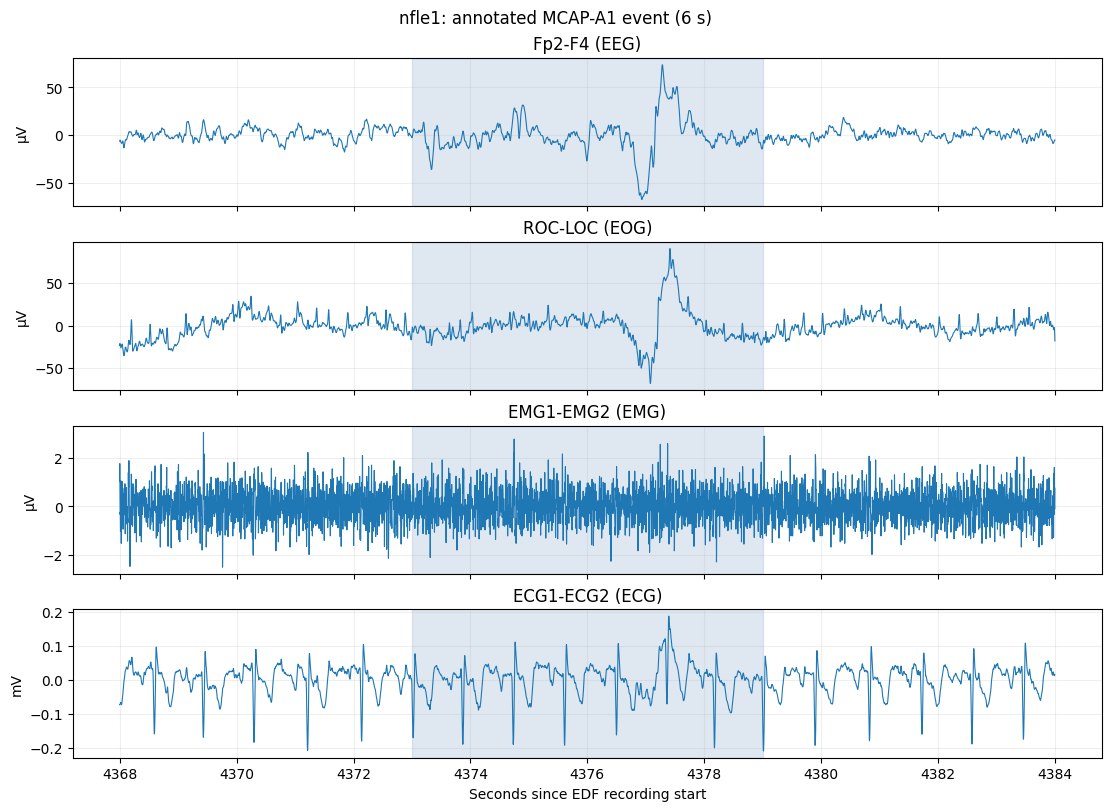

Saved figure to: /content/cap_sleep_data/outputs/nfle1_multimodal_CAP_A1.png


In [19]:
a1 = nfle1_cap.loc[nfle1_cap["Event"] == "MCAP-A1"].sort_values("Onset_s")
if a1.empty:
    raise ValueError("No A1 events available for visualization.")
example = a1.iloc[0]
start = max(0, float(example["Onset_s"]) - 5)
stop = min(recording_duration, float(example["Offset_s"]) + 5)
channels = [("Fp2-F4", "EEG", 1e6, "µV"), ("ROC-LOC", "EOG", 1e6, "µV"),
            ("EMG1-EMG2", "EMG", 1e6, "µV"), ("ECG1-ECG2", "ECG", 1e3, "mV")]
fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True, constrained_layout=True)
for ax, (channel, modality, factor, unit) in zip(axes, channels):
    if channel not in raw.ch_names:
        raise ValueError(f"Missing expected channel: {channel}")
    data, times = raw[[channel], int(start*raw.info["sfreq"]):int(stop*raw.info["sfreq"])]
    ax.plot(times, data[0] * factor, lw=0.8)
    ax.axvspan(example["Onset_s"], example["Offset_s"], color="lightsteelblue", alpha=0.4)
    ax.set(ylabel=f"{unit}", title=f"{channel} ({modality})")
    ax.grid(alpha=0.2)
axes[-1].set_xlabel("Seconds since EDF recording start")
fig.suptitle(f"nfle1: annotated {example['Event']} event ({example['Duration[s]']:g} s)")
fig.savefig(OUTPUT_DIR / "nfle1_multimodal_CAP_A1.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved figure to:", OUTPUT_DIR / "nfle1_multimodal_CAP_A1.png")

## 9. Interpretation and next steps

**What this notebook establishes:** annotation retrieval and cleaning for 88 selected participants; descriptive CAP A-phase summaries; an inventory of raw physiological channels in **one** EDF recording; preliminary timestamp alignment; and a representative four-modality visualization.

**What remains to validate:** consistency and quality of channels across participants; annotation/EDF clock agreement; the meaning of ambiguous DX/SX channels; sensor-specific preprocessing; construction of labelled A-phase versus non-A-phase windows; and participant-level train/test separation.

**Model comparison plan:** evaluate an EEG-only baseline against EEG + EOG + EMG and a broader cardiovascular-enhanced condition, **using the same participants and windows** for each fair comparison. No performance claims can be made yet.

**Reproducibility note:** Figures and CSV summaries are written to `OUTPUT_DIR` under Colab's temporary `/content/` filesystem. Copy them to persistent storage before the runtime resets.